<a href="https://colab.research.google.com/github/Sav200512/sp500-rfm-segmentation-cw/blob/main/Task_1_2_and_3_cw_(20232749_W2151870).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Task 1 Data Preparation and Feature Engineering**

---


**Task 1.1 Ticker selection and data acquisition**



In [1]:
import os, platform
import numpy as np
import pandas as pd
import yfinance as yf

In [2]:
SEED = 42
START, END = "2021-01-01", "2025-01-01"   # END is exclusive
BENCH = "^GSPC"

for folder in ["data/raw", "data/processed", "figures"]:
    os.makedirs(folder, exist_ok=True)

print("pandas", pd.__version__, "| numpy", np.__version__, "| yfinance", yf.__version__)

pandas 2.2.3 | numpy 2.4.6 | yfinance 0.2.66


In [3]:
url = 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies'
table = pd.read_html(url, storage_options={"User-Agent": "Mozilla/5.0"})
sp500_df = table[0]

sp500_df["Yahoo_Symbol"] = sp500_df["Symbol"].str.replace(".", "-", regex=False)
sp500_df["Retrieved_On"] = pd.Timestamp.now(tz="UTC").strftime("%Y-%m-%d %H:%M UTC")

sp500_df[["Symbol", "Yahoo_Symbol", "Security", "GICS Sector", "Retrieved_On"]].to_csv(
    "data/raw/sp500_tickers.csv", index=False)

tickers = sp500_df["Yahoo_Symbol"].tolist()
print("Total tickers extracted:", len(tickers), "| retrieved:", sp500_df["Retrieved_On"].iloc[0])
sp500_df[["Symbol", "Security", "GICS Sector"]].head(10)

Total tickers extracted: 503 | retrieved: 2026-11-24 08:35 UTC


,Symbol,Security,GICS Sector
0,MMM,3M,Industrials
1,AOS,A. O. Smith,Industrials
2,ABT,Abbott Laboratories,Health Care
3,ABBV,AbbVie,Health Care
4,ACN,Accenture,Information Technology
5,ADBE,Adobe Inc.,Information Technology
6,AMD,Advanced Micro Devices,Information Technology
7,AES,AES Corporation,Utilities
8,AFL,Aflac,Financials
9,A,Agilent Technologies,Health Care


In [4]:
frames = []
for i in range(0, len(tickers), 50):
    batch = tickers[i:i + 50]
    d = yf.download(batch, start=START, end=END, auto_adjust=False,
                    progress=False, threads=True)
    frames.append(d)
    print(f"Batch {i // 50 + 1} done ({len(batch)} tickers)")

raw = pd.concat(frames, axis=1)
close, adj_close, volume = raw["Close"], raw["Adj Close"], raw["Volume"]

bench = yf.download(BENCH, start=START, end=END, auto_adjust=False, progress=False)
if isinstance(bench.columns, pd.MultiIndex):
    bench.columns = bench.columns.get_level_values(0)

Batch 1 done (50 tickers)
Batch 2 done (50 tickers)
Batch 3 done (50 tickers)


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['FDXF']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Batch 4 done (50 tickers)


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['HONA']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Batch 5 done (50 tickers)
Batch 6 done (50 tickers)
Batch 7 done (50 tickers)


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['Q']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Batch 8 done (50 tickers)


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['SNDK']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Batch 9 done (50 tickers)


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['VYLR']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Batch 10 done (50 tickers)
Batch 11 done (3 tickers)


In [5]:
close.to_csv("data/raw/close_daily.csv.gz")
adj_close.to_csv("data/raw/adj_close_daily.csv.gz")
volume.to_csv("data/raw/volume_daily.csv.gz")
bench.to_csv("data/raw/gspc_daily.csv")

run_log = {
    "download_time_utc": pd.Timestamp.now(tz="UTC").isoformat(),
    "start": START, "end_exclusive": END, "benchmark": BENCH,
    "yfinance": yf.__version__, "pandas": pd.__version__,
    "python": platform.python_version(),
    "tickers_requested": len(tickers),
}
pd.Series(run_log).to_csv("data/raw/run_log.csv", header=["value"])

no_data = [t for t in tickers if t not in adj_close.columns or adj_close[t].isna().all()]
print("Requested:", len(tickers))
print("Returned with some data:", len(tickers) - len(no_data))
print("No data:", no_data)
print("Shares: first date", adj_close.index.min().date(), "| last date", adj_close.index.max().date())
print("Benchmark: first date", bench.index.min().date(), "| last date", bench.index.max().date(), "| rows", len(bench))
print("Share rows:", len(adj_close), "| shape close/adj/vol:", close.shape, adj_close.shape, volume.shape)


Requested: 503
Returned with some data: 498
No data: ['FDXF', 'HONA', 'Q', 'SNDK', 'VYLR']
Shares: first date 2021-01-04 | last date 2024-12-31
Benchmark: first date 2021-01-04 | last date 2024-12-31 | rows 1005
Share rows: 1005 | shape close/adj/vol: (1005, 503) (1005, 503) (1005, 503)


**Task 1.2 Data validation and alignment**

---



In [6]:
# Index-level checks
print("Duplicate dates (shares):", adj_close.index.duplicated().sum())
print("Duplicate dates (benchmark):", bench.index.duplicated().sum())
print("Dates sorted:", adj_close.index.is_monotonic_increasing)
print("Share and benchmark dates identical:", adj_close.index.equals(bench.index))

# Per-share diagnostics
cols = adj_close.columns
diag = pd.DataFrame(index=cols)
diag["first_valid"]     = [adj_close[t].first_valid_index() for t in cols]
diag["last_valid"]      = [adj_close[t].last_valid_index() for t in cols]
diag["n_obs"]           = adj_close.notna().sum()
diag["miss_adj"]        = adj_close.isna().sum()
diag["miss_close"]      = close[cols].isna().sum()
diag["miss_vol"]        = volume[cols].isna().sum()
diag["nonpos_price"]    = ((adj_close <= 0) | (close[cols] <= 0)).sum()
diag["neg_vol"]         = (volume[cols] < 0).sum()
diag["zero_vol"]        = (volume[cols] == 0).sum()

print("Trading sessions:", len(adj_close))
print(diag.describe().T[["min", "max"]])
diag[diag["n_obs"] < len(adj_close)].sort_values("n_obs")

Duplicate dates (shares): 0
Duplicate dates (benchmark): 0
Dates sorted: True
Share and benchmark dates identical: True
Trading sessions: 1005
                              min                  max
first_valid   2021-01-04 00:00:00  2024-03-27 00:00:00
last_valid    2024-12-31 00:00:00  2024-12-31 00:00:00
n_obs                         0.0               1005.0
miss_adj                      0.0               1005.0
miss_close                    0.0               1005.0
miss_vol                      0.0               1005.0
nonpos_price                  0.0                  0.0
neg_vol                       0.0                  0.0
zero_vol                      0.0                424.0


,first_valid,last_valid,n_obs,miss_adj,miss_close,miss_vol,nonpos_price,neg_vol,zero_vol
Ticker,,,,,,,,,
HONA,NaT,NaT,0,1005,1005,1005,0,0,0
FDXF,NaT,NaT,0,1005,1005,1005,0,0,0
SNDK,NaT,NaT,0,1005,1005,1005,0,0,0
Q,NaT,NaT,0,1005,1005,1005,0,0,0
VYLR,NaT,NaT,0,1005,1005,1005,0,0,0
GEV,2024-03-27,2024-12-31,193,812,812,812,0,0,0
SOLV,2024-03-26,2024-12-31,194,811,811,811,0,0,0
RDDT,2024-03-21,2024-12-31,197,808,808,808,0,0,0
VLTO,2023-10-04,2024-12-31,313,692,692,692,0,0,0


In [7]:
n_sessions = len(adj_close)
reasons = {}

for t, r in diag.iterrows():
    why = []
    if r["n_obs"] == 0:
        why.append("no price data in study period")
    elif r["n_obs"] < n_sessions:
        why.append(f"incomplete history: first price {r['first_valid'].date()} ({int(r['n_obs'])}/{n_sessions} sessions)")
    elif r["miss_close"] > 0 or r["miss_vol"] > 0:
        why.append("missing Close or Volume")
    if r["nonpos_price"] > 0:
        why.append("nonpositive price")
    if r["neg_vol"] > 0:
        why.append("negative volume")
    if why:
        reasons[t] = "; ".join(why)

exclusion_log = pd.DataFrame({"Ticker": list(reasons), "Reason": list(reasons.values())})
included = [t for t in cols if t not in reasons]

exclusion_log.to_csv("data/processed/exclusion_log.csv", index=False)
print("\nExclusion Log")
display(exclusion_log.head(20))
pd.Series(included, name="Ticker").to_csv("data/processed/included_shares.csv", index=False)


Exclusion Log


,Ticker,Reason
0,APP,incomplete history: first price 2021-04-15 (93...
1,CEG,incomplete history: first price 2022-01-19 (74...
2,COIN,incomplete history: first price 2021-04-14 (93...
3,EXE,incomplete history: first price 2021-02-10 (97...
4,FDXF,no price data in study period
5,GEHC,incomplete history: first price 2022-12-15 (51...
6,GEV,incomplete history: first price 2024-03-27 (19...
7,HONA,no price data in study period
8,HOOD,incomplete history: first price 2021-07-29 (86...
9,Q,no price data in study period


In [8]:
validation_summary = pd.DataFrame({
    "Rule": [
        "No data available",
        "Incomplete history",
        "Non-positive prices",
        "Negative volume"
    ],
    "Count": [
        (diag["n_obs"] == 0).sum(),
        ((diag["n_obs"] > 0) &
         (diag["n_obs"] < n_sessions)).sum(),
        (diag["nonpos_price"] > 0).sum(),
        (diag["neg_vol"] > 0).sum()
    ]
})

validation_summary.to_csv(
    "data/processed/validation_summary.csv",
    index=False
)

print("\nValidation Summary")
display(validation_summary)

print("Included:", len(included), "| Excluded:", len(exclusion_log))
print(exclusion_log["Reason"].str.split(":").str[0].value_counts())
print("Shares with any zero-volume days (not excluded, check):", int((diag.loc[included, "zero_vol"] > 0).sum()))


Validation Summary


,Rule,Count
0,No data available,5
1,Incomplete history,10
2,Non-positive prices,0
3,Negative volume,0


Included: 488 | Excluded: 15
Reason
incomplete history               10
no price data in study period     5
Name: count, dtype: int64
Shares with any zero-volume days (not excluded, check): 2


Exclusion Rationale

Shares with no available prices during the study period were excluded. Shares with incomplete histories were also excluded because they lack observations for part of the 2021–2024 period. Retaining such shares would produce unequal observation windows and inconsistent weekly return counts, reducing comparability across securities.

In [9]:
# Large one-day moves in Close can signal an unadjusted split or a data error.
close_ret = close.pct_change(fill_method=None)
big = (close_ret.abs() > 0.40).sum()
big = big[big > 0].sort_values(ascending=False)
print("Shares with a one-day Close move > 40%:", len(big))
print(big)

# Compare Adj Close and Close.
# Differences arise from corporate-action adjustments
# such as dividends, stock splits and spin-offs.
ratio = adj_close / close[cols]
print("Shares where Adj Close differs from Close on at least one date:", (ratio.sub(1).abs().max() > 1e-9).sum())

# Spot-check a known split (example: NVDA 10-for-1, June 2024)
print(close["NVDA"].loc["2024-06-05":"2024-06-14"])
print(adj_close["NVDA"].loc["2024-06-05":"2024-06-14"])

print("\nNVDA corporate actions:")
print(yf.Ticker("NVDA").actions.loc["2024"])

Shares with a one-day Close move > 40%: 7
Ticker
CVNA    5
APP     1
BE      1
DXCM    1
GL      1
HOOD    1
RDDT    1
dtype: int64
Shares where Adj Close differs from Close on at least one date: 405
Date
2024-06-05    122.440002
2024-06-06    120.998001
2024-06-07    120.888000
2024-06-10    121.790001
2024-06-11    120.910004
2024-06-12    125.199997
2024-06-13    129.610001
2024-06-14    131.880005
Name: NVDA, dtype: float64
Date
2024-06-05    122.091881
2024-06-06    120.653976
2024-06-07    120.544296
2024-06-10    121.443718
2024-06-11    120.576111
2024-06-12    124.854286
2024-06-13    129.252106
2024-06-14    131.515808
Name: NVDA, dtype: float64

NVDA corporate actions:
                           Dividends  Stock Splits
Date                                              
2024-03-05 00:00:00-05:00      0.004           0.0
2024-06-10 00:00:00-04:00      0.000          10.0
2024-06-11 00:00:00-04:00      0.010           0.0
2024-09-12 00:00:00-04:00      0.010           0.0
2024-

In [10]:
adj_inc = adj_close[included]
bench_adj = bench["Adj Close"]

w_shares = adj_inc.resample("W-FRI").last()
w_bench  = bench_adj.resample("W-FRI").last()

# Drop incomplete first/last calendar weeks (Mon-Fri window must sit inside the study period)
last_date = adj_close.index.max()
week_start = w_shares.index - pd.Timedelta(days=4)
keep = (week_start >= pd.Timestamp(START)) & (w_shares.index <= last_date)
w_shares, w_bench = w_shares[keep], w_bench[keep]

OBSERVATION_DATE = last_date

print(
    "Final common trading date:",
    OBSERVATION_DATE.date()
)

assert w_shares.index.equals(w_bench.index), "Week labels differ"

ret_shares = w_shares.pct_change(fill_method=None).iloc[1:]
ret_bench  = w_bench.pct_change(fill_method=None).iloc[1:]

ret_shares.to_csv(
    "data/processed/weekly_share_returns.csv.gz"
)

ret_bench.to_csv(
    "data/processed/weekly_benchmark_returns.csv"
)

print("Weekly price labels:", w_shares.index.min().date(), "to", w_shares.index.max().date(), f"({len(w_shares)})")
print("Weekly return observations:", len(ret_shares))
print("Any NaN in share returns:", ret_shares.isna().any().any())

Final common trading date: 2024-12-31
Weekly price labels: 2021-01-08 to 2024-12-27 (208)
Weekly return observations: 207
Any NaN in share returns: False


In [11]:
# 1. Zero-volume shares among the included set
zv = diag.loc[included, "zero_vol"]
print("Included shares with zero-volume days:")
for t in zv[zv > 0].index:
    v = volume[t]
    z = v[v == 0]

    print(
        f"  {t} | zero days: {len(z)} "
        f"| first: {z.index.min().date()} "
        f"| last: {z.index.max().date()} "
        f"| median non-zero volume: {v[v > 0].median():,.0f}"
    )

print("\nPotential volume anomalies:")
print(
    diag.loc[
        zv[zv > 20].index,
        ["zero_vol", "n_obs"]
    ]
)

# 2. The one-day moves over 40%
print("\nMoves over 40%:")
for t in big.index:
    moves = close_ret[t][close_ret[t].abs() > 0.40]
    print(f"\n{t} | included: {t in included}")
    print(moves.round(3).to_string())
    try:
        sp = yf.Ticker(t).splits
        print("  Yahoo splits 2021-2024:", sp.loc["2021":"2024"].to_dict() if len(sp) else "none")
    except Exception as e:
        print("  splits lookup failed:", e)

# 3. Late listings: any gaps after the first price?
late = diag[(diag["n_obs"] > 0) & (diag["n_obs"] < n_sessions)].copy()
late["gaps_after_first_price"] = [int(adj_close.loc[late.loc[t, "first_valid"]:, t].isna().sum()) for t in late.index]
print("\nLate listings:")
print(late[["first_valid", "n_obs", "gaps_after_first_price"]])

# Save diagnostics
diag.to_csv(
    "data/processed/share_diagnostics.csv"
)

Included shares with zero-volume days:
  FERG | zero days: 27 | first: 2021-01-07 | last: 2021-03-05 | median non-zero volume: 803,550
  SW | zero days: 424 | first: 2021-01-05 | last: 2024-07-05 | median non-zero volume: 600

Potential volume anomalies:
        zero_vol  n_obs
Ticker                 
FERG          27   1005
SW           424   1005

Moves over 40%:

CVNA | included: True
Date
2022-08-05    0.401
2022-12-07   -0.429
2023-01-12    0.460
2023-06-08    0.560
2023-07-19    0.402
  Yahoo splits 2021-2024: {}

APP | included: False
Date
2024-11-07    0.463
  Yahoo splits 2021-2024: none

BE | included: True
Date
2024-11-15    0.592
  Yahoo splits 2021-2024: none

DXCM | included: True
Date
2024-07-26   -0.407
  Yahoo splits 2021-2024: {Timestamp('2022-06-13 00:00:00-0400', tz='America/New_York'): 4.0}

GL | included: True
Date
2024-04-11   -0.531
  Yahoo splits 2021-2024: {}

HOOD | included: False
Date
2021-08-04    0.504
  Yahoo splits 2021-2024: none

RDDT | included: Fals

Survivorship Bias

The S&P 500 constituent list was obtained from the current Wikipedia S&P 500 page rather than a historical constituent database covering 2021–2024. As a result, survivorship bias may be present. Firms removed from the index during the study period are not represented, while companies added later are included. Therefore the sample reflects current constituents rather than the exact historical composition of the S&P 500 throughout the study period.

**Task 1.3**
---

**Task 1.3.1 Mean Weekly Return**

In [12]:
mean_weekly_return = ret_shares.mean()

print("Mean Weekly Return Summary")
print(mean_weekly_return.describe())

mean_weekly_return.to_csv(
    "data/processed/mean_weekly_return.csv",
    header=["Mean_Weekly_Return"]
)


Mean Weekly Return Summary
count    488.000000
mean       0.002857
std        0.002646
min       -0.004468
25%        0.001182
50%        0.002629
75%        0.004207
max        0.017772
dtype: float64


In [13]:
print(
    "Weekly observations used:",
    len(ret_shares)
)

print(
    "Any missing mean returns:",
    mean_weekly_return.isna().sum()
)

Weekly observations used: 207
Any missing mean returns: 0


**Task 1.3.2 weekly beta**

---

In [14]:
market_var = ret_bench.var()

betas = {}
for t in ret_shares.columns:
    betas[t] = ret_shares[t].cov(ret_bench) / market_var
weekly_beta = pd.Series(betas)

print("\nWeekly Beta Summary")
print(weekly_beta.describe())

weekly_beta.to_csv(
    "data/processed/weekly_beta.csv",
    header=["Weekly_Beta"]
)


Weekly Beta Summary
count    488.000000
mean       0.973868
std        0.406550
min        0.055453
25%        0.666634
50%        0.950609
75%        1.179289
max        3.778560
dtype: float64


In [15]:
risk_return_features = pd.DataFrame({
    "Ticker": mean_weekly_return.index,
    "Mean_Weekly_Return": mean_weekly_return.values,
    "Weekly_Beta": weekly_beta.values
})

print(
    risk_return_features.describe()
)

risk_return_features.to_csv(
    "data/processed/risk_return_features.csv",
    index=False
)

       Mean_Weekly_Return  Weekly_Beta
count          488.000000   488.000000
mean             0.002857     0.973868
std              0.002646     0.406550
min             -0.004468     0.055453
25%              0.001182     0.666634
50%              0.002629     0.950609
75%              0.004207     1.179289
max              0.017772     3.778560


Weekly Return and Weekly Beta

Weekly returns were calculated using Friday-ending adjusted closing prices and the percentage change from the previous completed week. The arithmetic mean weekly return over the full study period was used as the return feature. Weekly beta was calculated as the covariance between individual share returns and benchmark returns divided by the variance of benchmark returns. All calculations used 207 aligned weekly return observations and no missing weekly returns were imputed.

In [16]:
print(
    risk_return_features
    .sort_values(
        "Weekly_Beta",
        ascending=False
    )
    .head(10)
)


    Ticker  Mean_Weekly_Return  Weekly_Beta
94    CVNA            0.010964     3.778560
98     XYZ           -0.001554     2.504520
114   COHR            0.003887     2.139305
331   NVDA            0.013624     2.125953
440   TWLO           -0.002161     2.073379
432   TSLA            0.005275     2.045761
61      BE            0.003802     2.017079
361   PLTR            0.009613     2.003194
460    VRT            0.012583     2.001480
82     CCL            0.004095     1.958835


In [17]:
print("\nAligned weekly observations used:", len(ret_shares))
print("Missing returns:", risk_return_features.isna().sum().sum())


Aligned weekly observations used: 207
Missing returns: 0


**Task 1.4 Adapted RFM Calculations**

---



In [18]:
OBSERVATION_DATE = last_date
print(last_date)

2024-12-31 00:00:00


In [19]:
#RFM
#Volume > 2 * mean(previous 20 trading sessions)

vol_inc = volume[included]
close_inc = close[included]

baseline20 = vol_inc.shift(1).rolling(
    20,
    min_periods=20
).mean()



In [20]:
event_flag = vol_inc > (2 * baseline20)

#hight-volume event

print("Total events identified:")
print(int(event_flag.sum().sum()))

Total events identified:
18496


In [21]:
# Diagnostic: events flagged where the 20-session baseline is zero (any positive volume then qualifies)
zero_base_events = event_flag & (baseline20 == 0)
n_zb = zero_base_events.sum()
print("Events flagged on a zero baseline:", int(n_zb.sum()))
print("Shares affected:", n_zb[n_zb > 0].to_dict())

Events flagged on a zero baseline: 0
Shares affected: {}


**1.4.1 Recency**

---



In [22]:
#find most recent event
#observation date - event date

recency = {}

for ticker in included:

    events = event_flag.index[event_flag[ticker]]

    if len(events) == 0:
        recency[ticker] = np.nan
    else:
        recency[ticker] = (
            OBSERVATION_DATE -
            events.max()
        ).days

recency = pd.Series(
    recency,
    name="R"
)

print("\nShares excluded from RFM due to no events:")

print(recency[recency.isna()].index.tolist())


Shares excluded from RFM due to no events:
[]


In [23]:
print(recency.describe())
print("No event stocks:",recency.isna().sum())

count    488.000000
mean      20.389344
std       21.302843
min        4.000000
25%       11.000000
50%       11.000000
75%       15.000000
max      222.000000
Name: R, dtype: float64
No event stocks: 0


In [24]:
recency.to_csv("data/processed/recency.csv")

**Task 1.4.2 Frequency**

---



In [25]:
#Use the latest 60 trading sessions ending on observation date

last60_events = event_flag.tail(60)
frequency = last60_events.sum()

frequency.name = "F"

print(frequency.describe())


count    488.000000
mean       2.987705
std        1.328820
min        0.000000
25%        2.000000
50%        3.000000
75%        4.000000
max        8.000000
Name: F, dtype: float64


In [26]:
frequency.to_csv(
    "data/processed/frequency.csv"
)

**Task 1.4.3 Monetary**

---

In [27]:
# close*Volume
#sum of last 60 sessions

last60_close = close_inc.tail(60)
last60_vol = vol_inc.tail(60)

daily_traded_value = (
    last60_close *
    last60_vol
)

monetary = daily_traded_value.sum()

monetary.name = "M"

print(monetary.describe())

count    4.880000e+02
mean     3.930290e+10
std      1.288833e+11
min      1.297483e+09
25%      1.023194e+10
50%      1.668382e+10
75%      3.210048e+10
max      1.847697e+12
Name: M, dtype: float64


In [28]:
monetary.to_csv(
    "data/processed/monetary.csv"
)

In [29]:
#RFM TABLE
rfm_features = pd.concat(
    [
        recency,
        frequency,
        monetary
    ],
    axis=1
)

print(
    "Rows:",
    len(rfm_features)
)

print(
    "Missing values:"
)
print(
    rfm_features.isna().sum()
)

Rows: 488
Missing values:
R    0
F    0
M    0
dtype: int64


In [30]:
rfm_clustering = (
    rfm_features
    .dropna()
    .copy()
)

print("Shares for RFM clustering:",len(rfm_clustering))
rfm_clustering.to_csv("data/processed/rfm_clustering.csv")

Shares for RFM clustering: 488


In [31]:
example = "AAPL"

example_events = event_flag.index[
    event_flag[example]
]

print("\nWorked Example:", example)

print(
    "Observation Date:",
    OBSERVATION_DATE.date()
)

print(
    "Last Event Date:",
    example_events.max().date()
)

print(
    "\nRFM Values"
)

print(
    rfm_features.loc[example]
)


Worked Example: AAPL
Observation Date: 2024-12-31
Last Event Date: 2024-12-20

RFM Values
R    1.100000e+01
F    2.000000e+00
M    6.233034e+11
Name: AAPL, dtype: float64


**Worked RFM Example**

R (Recency) measures the number of calendar days between the observation date (2024-12-31) and the most recent qualifying high-volume event. Smaller values indicate more recent trading activity.

F (Frequency) measures the number of qualifying high-volume events occurring during the most recent 60 trading sessions.

M (Monetary) represents the approximate traded value over the most recent 60 trading sessions, calculated as Close × Volume and summed across all days. It is a liquidity proxy rather than a measure of profitability, company value or investor returns.

**1.5 Metric interpretation and supporting evidence**
---

In [32]:
ex = "AAPL"
v = volume[ex]
base = v.shift(1).rolling(20, min_periods=20).mean()   # previous 20 sessions, excludes the day tested
thr = 2 * base
flag = v > thr

# Recency
last_event = flag[flag].index.max()
r_val = (OBSERVATION_DATE - last_event).days
print("Observation date:", OBSERVATION_DATE.date(), "| latest event:", last_event.date(), "| R =", r_val, "days")
display(pd.DataFrame({"Volume": v, "Baseline20": base, "Threshold_2x": thr, "Qualifies": flag})
        .loc[last_event - pd.Timedelta(days=3):].head(6).round(0))

# Frequency
win = flag.tail(60)
print("\n60-session window:", win.index.min().date(), "to", win.index.max().date())
print("Qualifying days:", [d.date() for d in win[win].index], "-> F =", int(win.sum()))

# Monetary
dtv = (close[ex] * volume[ex]).tail(60)
print("\nLast 3 daily traded values (USD):")
for d, x in dtv.tail(3).items():
    print(d.date(), f"${x:,.0f}")
print(f"M = sum of 60 days = ${dtv.sum():,.0f} (about ${dtv.sum()/1e9:,.0f} billion)")

assert r_val == rfm_features.loc[ex, "R"]
assert int(win.sum()) == rfm_features.loc[ex, "F"]
assert np.isclose(dtv.sum(), rfm_features.loc[ex, "M"])

Observation date: 2024-12-31 | latest event: 2024-12-20 | R = 11 days


,Volume,Baseline20,Threshold_2x,Qualifies
Date,,,,
2024-12-17,51356400,42354720.0,84709440.0,False
2024-12-18,56774100,42690855.0,85381710.0,False
2024-12-19,60882300,43718970.0,87437940.0,False
2024-12-20,147495300,45004605.0,90009210.0,True
2024-12-23,40858800,50273955.0,100547910.0,False
2024-12-24,23234700,50408480.0,100816960.0,False



60-session window: 2024-10-07 to 2024-12-31
Qualifying days: [datetime.date(2024, 11, 25), datetime.date(2024, 12, 20)] -> F = 2

Last 3 daily traded values (USD):
2024-12-27 $10,825,590,972
2024-12-30 $8,967,601,391
2024-12-31 $9,886,756,822
M = sum of 60 days = $623,303,377,707 (about $623 billion)


In [33]:
features = (risk_return_features.set_index("Ticker")
            .join(rfm_features, how="inner"))
features["log1p_M"] = np.log1p(features["M"])
features["AsOf"] = OBSERVATION_DATE.date()
features.to_csv("data/processed/feature_table.csv")

num = ["Mean_Weekly_Return", "Weekly_Beta", "R", "F", "M", "log1p_M"]
summary = features[num].describe().T[["count", "mean", "50%", "std", "min", "max"]]
summary = summary.rename(columns={"50%": "median"})
summary["skew"] = features[num].skew()
summary.to_csv("data/processed/feature_summary.csv")
display(summary)

print("Shares with F = 0:", int((features["F"] == 0).sum()))
print("Most common R values:\n", features["R"].value_counts().head(5))

,count,mean,median,std,min,max,skew
Mean_Weekly_Return,488.0,2.857285e-03,2.629157e-03,2.646164e-03,-4.468095e-03,1.777248e-02,0.869155
Weekly_Beta,488.0,9.738679e-01,9.506092e-01,4.065500e-01,5.545281e-02,3.778560e+00,1.104295
R,488.0,2.038934e+01,1.100000e+01,2.130284e+01,4.000000e+00,2.220000e+02,3.653409
F,488.0,2.987705e+00,3.000000e+00,1.328820e+00,0.000000e+00,8.000000e+00,0.428575
M,488.0,3.930290e+10,1.668382e+10,1.288833e+11,1.297483e+09,1.847697e+12,11.707304
log1p_M,488.0,2.368089e+01,2.353770e+01,9.405987e-01,2.098369e+01,2.824496e+01,1.083670


Shares with F = 0: 10
Most common R values:
 R
11    354
36     17
55     11
60      6
46      6
Name: count, dtype: int64


In [34]:
ok_base = True
for t in [x for x in ["AAPL", "MSFT", "JPM"] if x in included]:
    i = len(volume) - 1
    manual = volume[t].iloc[i-20:i].mean()          # 20 sessions before the final day
    ok_base &= np.isclose(manual, baseline20[t].iloc[-1])

F_check = (vol_inc > 2 * vol_inc.shift(1).rolling(20).mean()).tail(60).sum()
common = sorted(set(risk_return_features["Ticker"]) & set(rfm_clustering.index))

checks = pd.DataFrame([
    ("Baseline = mean of preceding 20 sessions, excluding tested day", bool(ok_base)),
    ("All included shares have >= 80 valid sessions (20 baseline + 60 window)", bool((diag.loc[included, "n_obs"] >= 80).all())),
    ("Frequency/Monetary window is exactly 60 sessions", len(event_flag.tail(60)) == 60),
    ("Shares with no qualifying event (R left missing, not 0)", int(recency.isna().sum())),
    ("Shares with an event on the observation date (R = 0)", int((recency == 0).sum())),
    ("F recomputed independently matches", bool((F_check == frequency).all())),
    ("Common valid share set size (return/beta and RFM)", len(common)),
], columns=["Check", "Result"])

display(checks)
checks.to_csv("data/processed/validation_checks.csv", index=False)
pd.Series(common, name="Ticker").to_csv("data/processed/common_share_set.csv", index=False)

,Check,Result
0,"Baseline = mean of preceding 20 sessions, excl...",True
1,All included shares have >= 80 valid sessions ...,True
2,Frequency/Monetary window is exactly 60 sessions,True
3,Shares with no qualifying event (R left missin...,0
4,Shares with an event on the observation date (...,0
5,F recomputed independently matches,True
6,Common valid share set size (return/beta and RFM),488


In [35]:
n_nodata = int((diag["n_obs"] == 0).sum())
n_incomplete = int(((diag["n_obs"] > 0) & (diag["n_obs"] < n_sessions)).sum())
n_other = len(cols) - n_nodata - n_incomplete - len(included)

flow = pd.DataFrame({
    "Stage": [f"Tickers on Wikipedia list (retrieved {sp500_df['Retrieved_On'].iloc[0]})",
              "Excluded: no Yahoo price data for 2021-2024",
              "Excluded: incomplete history (first price after the first session)",
              "Excluded: other validation failures",
              "Included in analysis"],
    "Shares": [len(tickers), n_nodata, n_incomplete, n_other, len(included)]
})
display(flow)
flow.to_csv("data/processed/inclusion_flow.csv", index=False)

display(exclusion_log)

,Stage,Shares
0,Tickers on Wikipedia list (retrieved 2026-11-2...,503
1,Excluded: no Yahoo price data for 2021-2024,5
2,Excluded: incomplete history (first price afte...,10
3,Excluded: other validation failures,0
4,Included in analysis,488


,Ticker,Reason
0,APP,incomplete history: first price 2021-04-15 (93...
1,CEG,incomplete history: first price 2022-01-19 (74...
2,COIN,incomplete history: first price 2021-04-14 (93...
3,EXE,incomplete history: first price 2021-02-10 (97...
4,FDXF,no price data in study period
5,GEHC,incomplete history: first price 2022-12-15 (51...
6,GEV,incomplete history: first price 2024-03-27 (19...
7,HONA,no price data in study period
8,HOOD,incomplete history: first price 2021-07-29 (86...
9,Q,no price data in study period


**Task 2**
---

In [36]:
import os, platform
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import sklearn, scipy
from scipy.cluster.hierarchy import linkage, dendrogram, cut_tree
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

In [37]:
SEED = 42
for f in ["data/processed", "figures"]:
    os.makedirs(f, exist_ok=True)
print("python", platform.python_version(), "| pandas", pd.__version__, "| numpy", np.__version__,
      "| scikit-learn", sklearn.__version__, "| scipy", scipy.__version__)

# Load Task 1 outputs (skipped if they already exist in this session)
if "features" not in globals():
    features = pd.read_csv("data/processed/feature_table.csv", index_col=0)
if "common" not in globals():
    common = pd.read_csv("data/processed/common_share_set.csv")["Ticker"].tolist()
if "sp500_df" not in globals():
    sp500_df = pd.read_csv("data/raw/sp500_tickers.csv")
if "log1p_M" not in features.columns:
    features["log1p_M"] = np.log1p(features["M"])

df = features.loc[common].copy()
df["Sector"] = sp500_df.set_index("Yahoo_Symbol")["GICS Sector"].reindex(df.index)
RR_COLS  = ["Mean_Weekly_Return", "Weekly_Beta"]
RFM_COLS = ["R", "F", "log1p_M"]
print("Common valid shares:", len(df), "| missing:", int(df[RR_COLS + RFM_COLS].isna().sum().sum()))

python 3.13.18 | pandas 2.2.3 | numpy 2.4.6 | scikit-learn 1.6.1 | scipy 1.16.3
Common valid shares: 488 | missing: 0


**Task 2.1 Feature preparation**

---



,skew,n_abs_z_gt_3
Mean_Weekly_Return,0.87,6.0
Weekly_Beta,1.10,2.0
R,3.65,11.0
F,0.43,5.0
M,11.71,NaN
log1p_M,1.08,7.0


Mean_Weekly_Return: most extreme -> ['SMCI', 'NVDA', 'VRT']
Weekly_Beta: most extreme -> ['CVNA', 'XYZ', 'COHR']
R: most extreme -> ['NVDA', 'WEC', 'DUK']
F: most extreme -> ['CI', 'HSY', 'XEL']
log1p_M: most extreme -> ['TSLA', 'NVDA', 'AAPL']


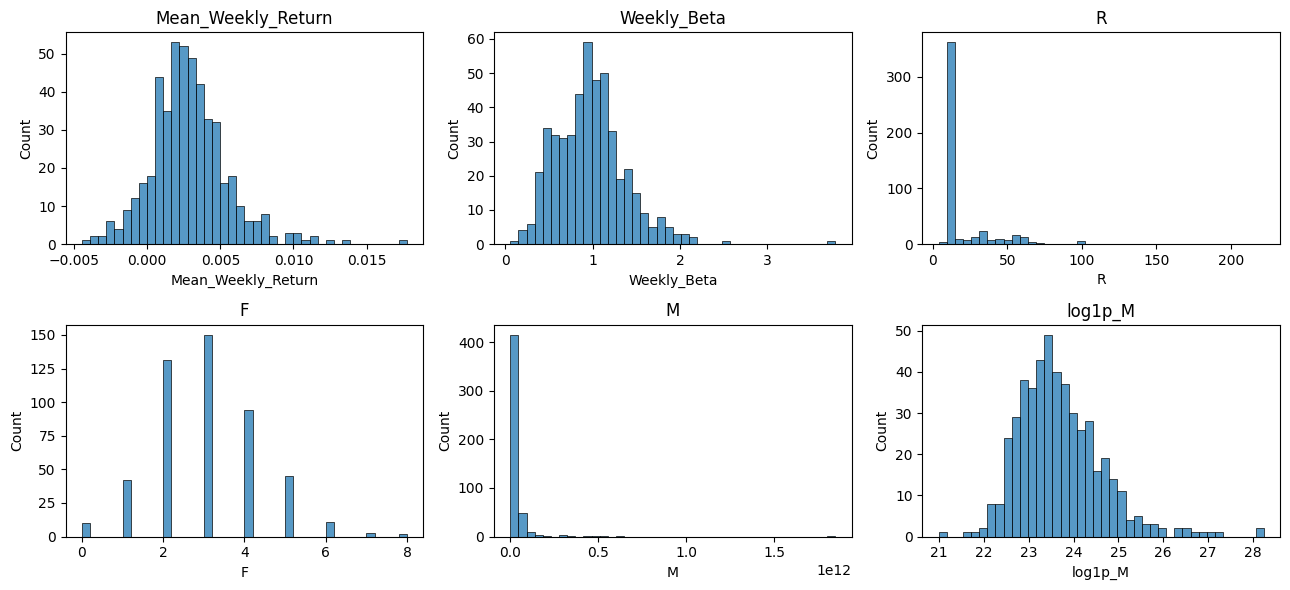

Means ~0: 0.0 0.0 | SD = 1: [1.0, 1.0] [1.0, 1.0, 1.0]


In [38]:

cols_all = RR_COLS + ["R", "F", "M", "log1p_M"]
diag_feat = pd.DataFrame({"skew": df[cols_all].skew()})
zs = (df[RR_COLS + RFM_COLS] - df[RR_COLS + RFM_COLS].mean()) / df[RR_COLS + RFM_COLS].std()
diag_feat["n_abs_z_gt_3"] = (zs.abs() > 3).sum().reindex(diag_feat.index)
display(diag_feat.round(2))
for c in RR_COLS + RFM_COLS:
    print(f"{c}: most extreme ->", zs[c].abs().sort_values(ascending=False).head(3).index.tolist())

fig, ax = plt.subplots(2, 3, figsize=(13, 6))
for a, c in zip(ax.ravel(), ["Mean_Weekly_Return", "Weekly_Beta", "R", "F", "M", "log1p_M"]):
    sns.histplot(df[c], bins=40, ax=a); a.set_title(c)
plt.tight_layout(); plt.savefig("figures/feature_distributions.png", dpi=150); plt.show()

# Two matrices, each standardised on its own
X_rr  = pd.DataFrame(StandardScaler().fit_transform(df[RR_COLS]),  index=df.index, columns=RR_COLS)
X_rfm = pd.DataFrame(StandardScaler().fit_transform(df[RFM_COLS]), index=df.index, columns=RFM_COLS)
print("Means ~0:", round(float(X_rr.mean().abs().max()), 6), round(float(X_rfm.mean().abs().max()), 6),
      "| SD = 1:", X_rr.std(ddof=0).round(3).tolist(), X_rfm.std(ddof=0).round(3).tolist())
df[RR_COLS + RFM_COLS].to_csv("data/processed/matrices_original_units.csv")
X_rr.to_csv("data/processed/X_risk_return_scaled.csv"); X_rfm.to_csv("data/processed/X_rfm_scaled.csv")

**Task 2.2 and 2.3 Diagnostics for k = 2 to 8**

---



In [39]:
K_RANGE = range(2, 9)

def ward_scan(X):
    Zm = linkage(X.values, method="ward", metric="euclidean")
    rows = []
    for k in K_RANGE:
        lab = cut_tree(Zm, n_clusters=k).ravel()
        sizes = np.bincount(lab)
        rows.append({"k": k, "silhouette": silhouette_score(X, lab), "min_size": int(sizes.min()),
                     "sizes": sorted(sizes.tolist(), reverse=True)})
    return Zm, pd.DataFrame(rows).set_index("k")

def km_scan(X):
    rows = []
    for k in K_RANGE:
        km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(X)
        sizes = np.bincount(km.labels_)
        rows.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(X, km.labels_),
                     "min_size": int(sizes.min()), "sizes": sorted(sizes.tolist(), reverse=True)})
    return pd.DataFrame(rows).set_index("k")

Z_rr,  ward_rr  = ward_scan(X_rr)
Z_rfm, ward_rfm = ward_scan(X_rfm)
km_rr, km_rfm   = km_scan(X_rr), km_scan(X_rfm)

for name, t in [("Ward | risk/return", ward_rr), ("Ward | RFM", ward_rfm),
                ("K-means | risk/return", km_rr), ("K-means | RFM", km_rfm)]:
    print(name); display(t.round(3))



Ward | risk/return


,silhouette,min_size,sizes
k,,,
2,0.340,92,"[396, 92]"
3,0.293,92,"[212, 184, 92]"
4,0.265,92,"[184, 114, 98, 92]"
5,0.287,48,"[136, 114, 98, 92, 48]"
6,0.304,5,"[136, 114, 98, 87, 48, 5]"
7,0.306,5,"[114, 114, 98, 87, 48, 22, 5]"
8,0.314,5,"[114, 114, 98, 56, 48, 31, 22, 5]"


Ward | RFM


,silhouette,min_size,sizes
k,,,
2,0.369,86,"[402, 86]"
3,0.261,86,"[223, 179, 86]"
4,0.251,86,"[179, 137, 86, 86]"
5,0.270,10,"[179, 137, 86, 76, 10]"
6,0.291,10,"[161, 137, 86, 76, 18, 10]"
7,0.280,10,"[137, 90, 86, 76, 71, 18, 10]"
8,0.282,1,"[137, 90, 86, 76, 71, 18, 9, 1]"


K-means | risk/return


,inertia,silhouette,min_size,sizes
k,,,,
2,625.010,0.387,143,"[345, 143]"
3,464.071,0.328,119,"[203, 166, 119]"
4,373.954,0.326,40,"[162, 154, 132, 40]"
5,311.854,0.339,28,"[164, 127, 114, 55, 28]"
6,267.455,0.336,5,"[145, 132, 108, 56, 42, 5]"
7,228.707,0.355,16,"[144, 87, 79, 76, 48, 38, 16]"
8,196.031,0.358,5,"[139, 82, 76, 71, 48, 37, 30, 5]"


K-means | RFM


,inertia,silhouette,min_size,sizes
k,,,,
2,1071.585,0.424,68,"[420, 68]"
3,800.746,0.325,63,"[274, 151, 63]"
4,612.475,0.341,61,"[214, 122, 91, 61]"
5,517.075,0.358,11,"[200, 122, 87, 68, 11]"
6,439.830,0.345,11,"[143, 120, 106, 68, 40, 11]"
7,390.891,0.340,1,"[139, 119, 103, 65, 46, 15, 1]"
8,343.594,0.343,1,"[151, 105, 89, 65, 48, 18, 11, 1]"


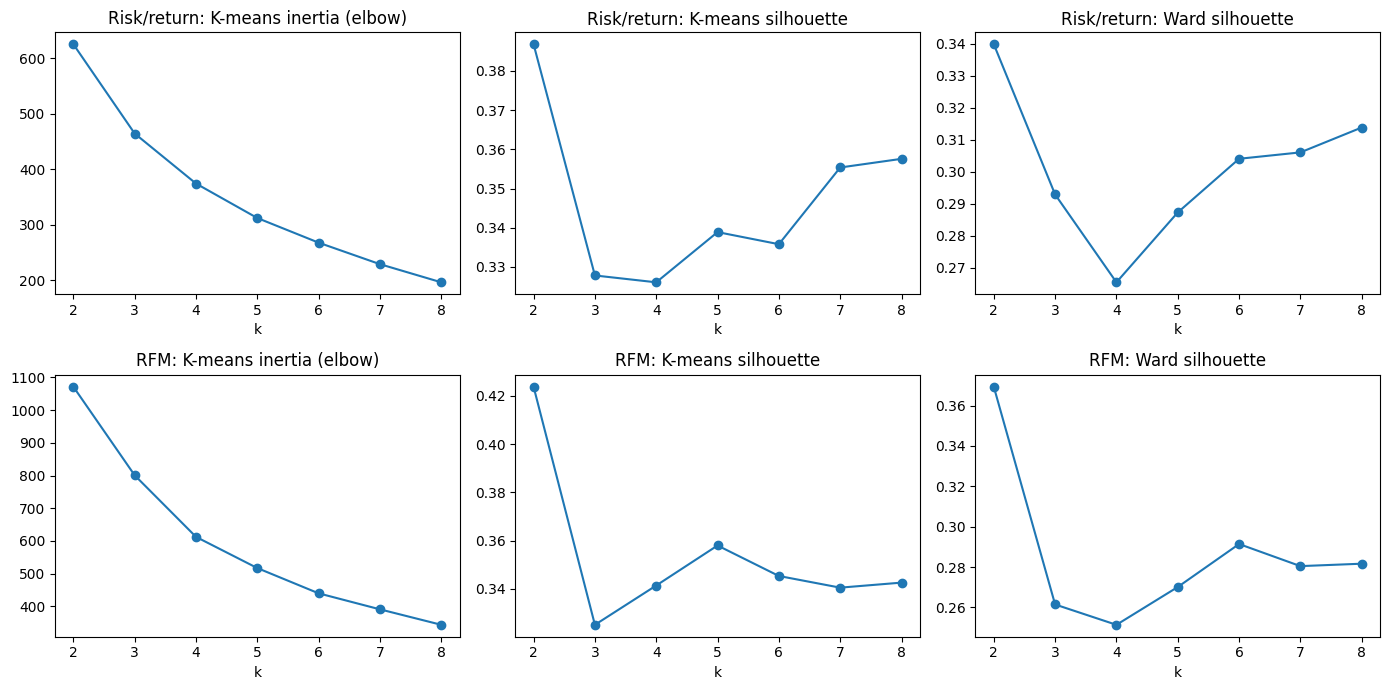

risk/return, k=3: single-start inertia 464.1 to 464.1 | n_init=20 best 464.1
RFM, k=3: single-start inertia 800.7 to 919.2 | n_init=20 best 800.7


In [40]:
fig, ax = plt.subplots(2, 3, figsize=(14, 7))
for r, (name, kt, wt) in enumerate([("Risk/return", km_rr, ward_rr), ("RFM", km_rfm, ward_rfm)]):
    ax[r, 0].plot(kt.index, kt["inertia"], "o-");    ax[r, 0].set(title=f"{name}: K-means inertia (elbow)", xlabel="k")
    ax[r, 1].plot(kt.index, kt["silhouette"], "o-"); ax[r, 1].set(title=f"{name}: K-means silhouette", xlabel="k")
    ax[r, 2].plot(wt.index, wt["silhouette"], "o-"); ax[r, 2].set(title=f"{name}: Ward silhouette", xlabel="k")
plt.tight_layout(); plt.savefig("figures/k_selection.png", dpi=150); plt.show()

# K-means initialisation stability: 10 single starts vs best of 20
K_CHECK = 3
for name, X in [("risk/return", X_rr), ("RFM", X_rfm)]:
    single = [KMeans(n_clusters=K_CHECK, n_init=1, random_state=s).fit(X).inertia_ for s in range(10)]
    best = KMeans(n_clusters=K_CHECK, n_init=20, random_state=SEED).fit(X).inertia_
    print(f"{name}, k={K_CHECK}: single-start inertia {min(single):.1f} to {max(single):.1f} | n_init=20 best {best:.1f}")

In [41]:
# Final choices (justify in the report): k = 2 has the highest silhouette in all four solutions
# (Ward RR 0.340, K-means RR 0.387, Ward RFM 0.369, K-means RFM 0.424) and the smallest cluster still has 68+ shares.
K_HC_RR, K_KM_RR, K_HC_RFM, K_KM_RFM = 2, 2, 2, 2

def suggest_k(tbl, min_frac=0.05):
    floor = max(5, int(min_frac * len(df)))
    ok = tbl[tbl["min_size"] >= floor]
    return int((ok if len(ok) else tbl)["silhouette"].idxmax())

chosen = {}
for key, val, tbl in [("HC_RR", K_HC_RR, ward_rr), ("KM_RR", K_KM_RR, km_rr),
                      ("HC_RFM", K_HC_RFM, ward_rfm), ("KM_RFM", K_KM_RFM, km_rfm)]:
    chosen[key] = val if val is not None else suggest_k(tbl)
    print(f"{key}: k = {chosen[key]}", "(set by you)" if val is not None else "(SUGGESTED, override above)")

HC_RR: k = 2 (set by you)
KM_RR: k = 2 (set by you)
HC_RFM: k = 2 (set by you)
KM_RFM: k = 2 (set by you)


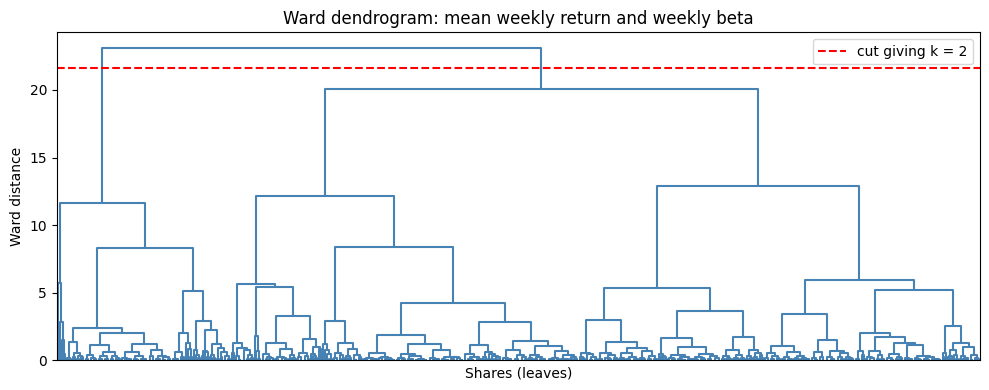

In [42]:
def draw_dendro(Zm, k_cut, title, fname):
    plt.figure(figsize=(10, 4))
    dendrogram(Zm, no_labels=True, color_threshold=0, above_threshold_color="steelblue")
    n = Zm.shape[0] + 1
    h = (Zm[n - k_cut - 1, 2] + Zm[n - k_cut, 2]) / 2
    plt.axhline(h, color="red", ls="--", label=f"cut giving k = {k_cut}")
    plt.title(title); plt.xlabel("Shares (leaves)"); plt.ylabel("Ward distance"); plt.legend()
    plt.tight_layout(); plt.savefig(fname, dpi=150); plt.show()

draw_dendro(Z_rr,  chosen["HC_RR"],  "Ward dendrogram: mean weekly return and weekly beta", "figures/dendrogram_risk_return.png")


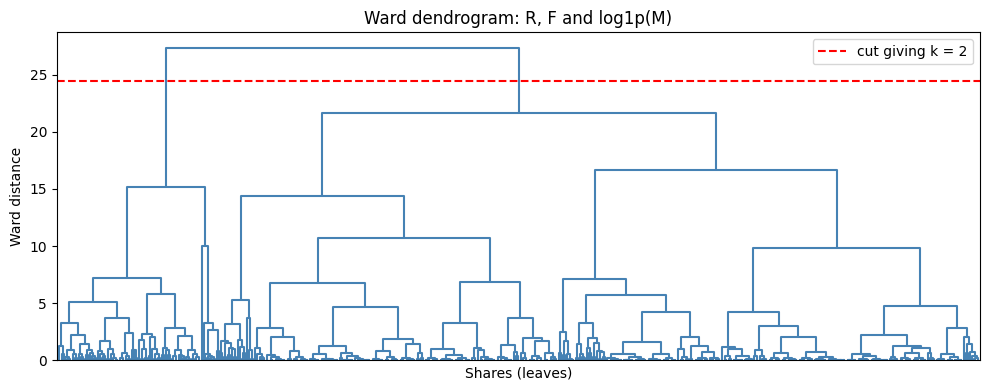

Ward risk/return: k=2 -> k=3


k=3,0,1,2
k=2,,,
0,184,0,212
1,0,92,0


Ward RFM: k=2 -> k=3


k=3,0,1,2
k=2,,,
0,223,179,0
1,0,0,86


In [43]:
draw_dendro(Z_rfm, chosen["HC_RFM"], "Ward dendrogram: R, F and log1p(M)",                  "figures/dendrogram_rfm.png")

for Zm, name, k in [(Z_rr, "risk/return", chosen["HC_RR"]), (Z_rfm, "RFM", chosen["HC_RFM"])]:
    a, b = cut_tree(Zm, n_clusters=k).ravel(), cut_tree(Zm, n_clusters=k + 1).ravel()
    print(f"Ward {name}: k={k} -> k={k+1}")
    display(pd.crosstab(a, b, rownames=[f"k={k}"], colnames=[f"k={k+1}"]))

In [44]:
# Original-unit profiles for k = 2, 3, 4: interpretability evidence for choosing k (Ward and K-means)
def profile_k(labels, cols):
    g = df.assign(Cluster=labels).groupby("Cluster")
    p = g[cols].mean()
    if "R" in cols:
        p["M_median_$bn"] = (g["M"].median() / 1e9).round(1)
    p["n"] = g.size()
    return p

for name, Zm, X, cols in [("risk/return", Z_rr, X_rr, RR_COLS), ("RFM", Z_rfm, X_rfm, ["R", "F"])]:
    for k in [2, 3, 4]:
        print(f"\nWard {name}, k={k}")
        display(profile_k(cut_tree(Zm, n_clusters=k).ravel(), cols).round(4))
        print(f"K-means {name}, k={k}")
        display(profile_k(KMeans(n_clusters=k, n_init=20, random_state=SEED).fit_predict(X), cols).round(4))


Ward risk/return, k=2


,Mean_Weekly_Return,Weekly_Beta,n
Cluster,,,
0,0.0021,0.8985,396
1,0.0063,1.2981,92


K-means risk/return, k=2


,Mean_Weekly_Return,Weekly_Beta,n
Cluster,,,
0,0.0018,0.8178,345
1,0.0053,1.3505,143



Ward risk/return, k=3


,Mean_Weekly_Return,Weekly_Beta,n
Cluster,,,
0,0.0015,1.1998,184
1,0.0063,1.2981,92
2,0.0025,0.6371,212


... (14 outputs left out)


Ward RFM, k=4


,R,F,M_median_$bn,n
Cluster,,,,
0,11.2847,2.6350,8.5,137
1,12.1453,2.9385,34.3,179
2,15.4419,4.6628,13.4,86
3,57.0000,1.9767,21.5,86


K-means RFM, k=4


,R,F,M_median_$bn,n
Cluster,,,,
0,13.2897,2.3692,13.3,214
1,13.9426,4.5492,12.8,122
2,66.0164,1.6721,21.2,61
3,15.1429,3.2308,60.2,91


**Task 2.4 Profiles, 2D plots and algorithm comparison**

---

In [45]:
assign = pd.DataFrame(index=df.index)
assign["HC_RR"]  = cut_tree(Z_rr, n_clusters=chosen["HC_RR"]).ravel()
assign["KM_RR"]  = KMeans(chosen["KM_RR"],  n_init=20, random_state=SEED).fit_predict(X_rr)
assign["HC_RFM"] = cut_tree(Z_rfm, n_clusters=chosen["HC_RFM"]).ravel()
assign["KM_RFM"] = KMeans(chosen["KM_RFM"], n_init=20, random_state=SEED).fit_predict(X_rfm)

def profile(col, cols):
    g = df.assign(Cluster=assign[col]).groupby("Cluster")
    p = g[cols].mean()
    if "M" in cols:
        p["M_mean_$bn"] = (p.pop("M") / 1e9).round(1)
        p["M_median_$bn"] = (g["M"].median() / 1e9).round(1)
    p["n"] = g.size()
    return p

for col, cols in [("HC_RR", RR_COLS), ("KM_RR", RR_COLS), ("HC_RFM", ["R", "F", "M"]), ("KM_RFM", ["R", "F", "M"])]:
    pr = profile(col, cols)
    print(f"\n{col}: profile in original units")
    display(pr.round(4)); pr.to_csv(f"data/processed/profile_{col}.csv")


HC_RR: profile in original units


,Mean_Weekly_Return,Weekly_Beta,n
Cluster,,,
0,0.0021,0.8985,396
1,0.0063,1.2981,92



KM_RR: profile in original units


,Mean_Weekly_Return,Weekly_Beta,n
Cluster,,,
0,0.0018,0.8178,345
1,0.0053,1.3505,143



HC_RFM: profile in original units


,R,F,M_mean_$bn,M_median_$bn,n
Cluster,,,,,
0,12.5572,3.2040,37.4,15.4,402
1,57.0000,1.9767,48.2,21.5,86



KM_RFM: profile in original units


,R,F,M_mean_$bn,M_median_$bn,n
Cluster,,,,,
0,13.4357,3.1833,32.6,15.6,420
1,63.3382,1.7794,80.7,22.3,68


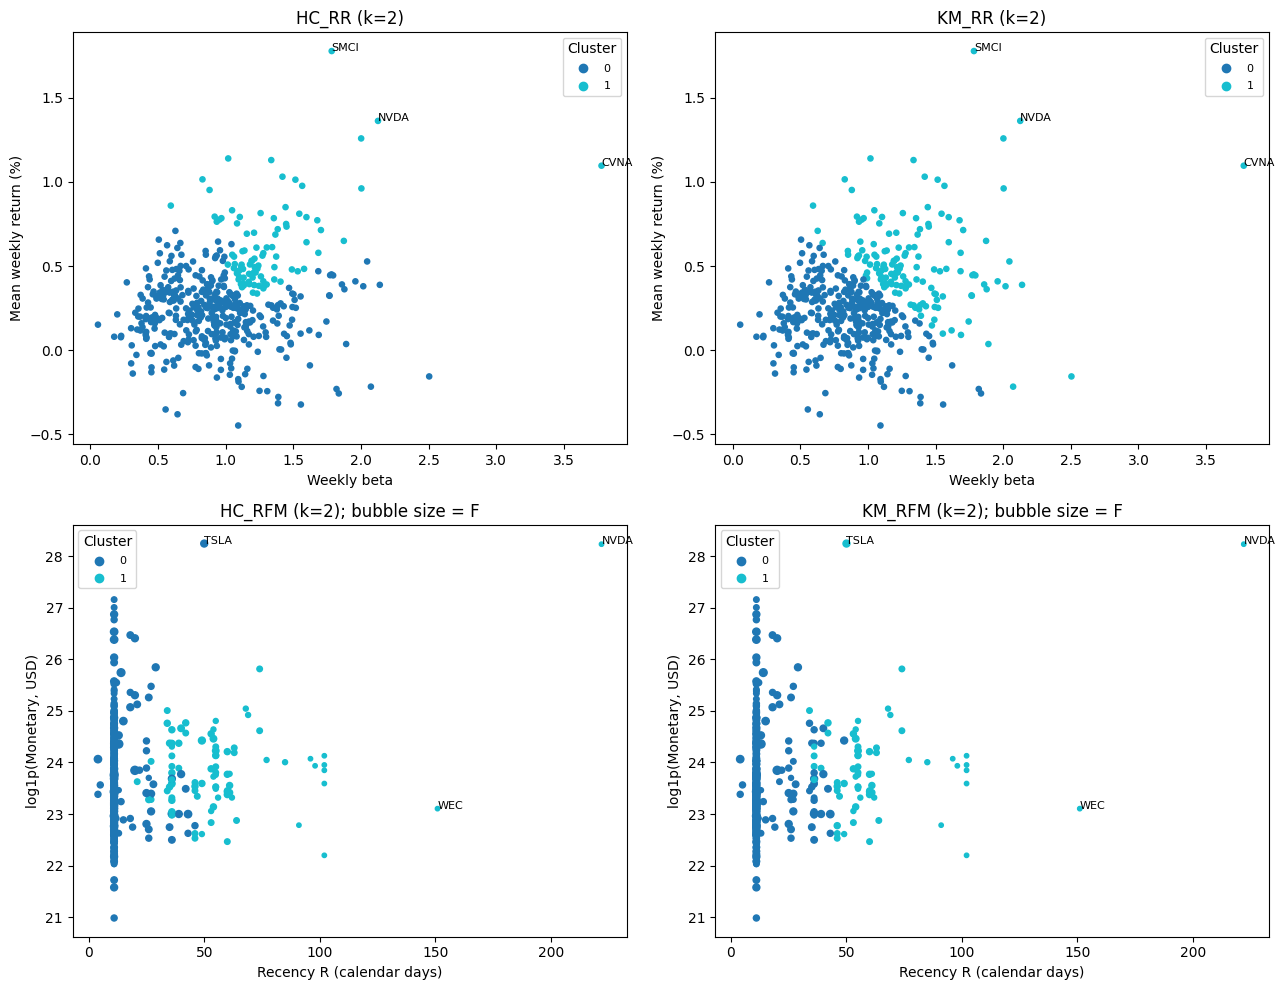

In [46]:
# 2D plots in original units: risk/return directly; RFM shown as R vs log1p(M), bubble size = F
def label_extremes(ax, xs, ys, names, n=3):
    idx = np.argsort(-(np.abs((xs - xs.mean()) / xs.std()) + np.abs((ys - ys.mean()) / ys.std())))[:n]
    for i in idx:
        ax.annotate(names[i], (xs[i], ys[i]), fontsize=8)

fig, ax = plt.subplots(2, 2, figsize=(13, 10))
for j, col in enumerate(["HC_RR", "KM_RR"]):
    x, y = df["Weekly_Beta"].values, (df["Mean_Weekly_Return"] * 100).values
    sc = ax[0, j].scatter(x, y, c=assign[col], cmap="tab10", s=14)
    ax[0, j].set(title=f"{col} (k={assign[col].nunique()})", xlabel="Weekly beta", ylabel="Mean weekly return (%)")
    label_extremes(ax[0, j], x, y, df.index.values)
    ax[0, j].legend(*sc.legend_elements(), title="Cluster", fontsize=8)
for j, col in enumerate(["HC_RFM", "KM_RFM"]):
    x, y = df["R"].values, df["log1p_M"].values
    sc = ax[1, j].scatter(x, y, c=assign[col], cmap="tab10", s=10 + 3 * df["F"].values)
    ax[1, j].set(title=f"{col} (k={assign[col].nunique()}); bubble size = F",
                 xlabel="Recency R (calendar days)", ylabel="log1p(Monetary, USD)")
    label_extremes(ax[1, j], x, y, df.index.values)
    ax[1, j].legend(*sc.legend_elements(), title="Cluster", fontsize=8)
plt.tight_layout(); plt.savefig("figures/cluster_scatter.png", dpi=150); plt.show()
# Note: the RFM panels show R and log1p(M) only; F is shown by bubble size. No dimensionality reduction is used.

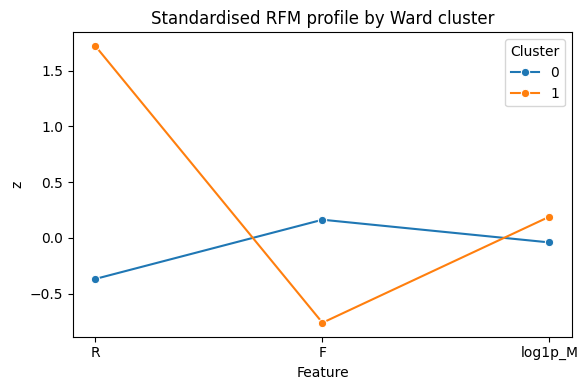

ARI Ward vs K-means: risk/return = 0.599 | RFM = 0.780


K-means,0,1
Ward,,
0,345,51
1,0,92


K-means,0,1
Ward,,
0,400,2
1,20,66


ARI risk/return Ward vs RFM Ward: 0.03


In [47]:
# Standardised profile lines (Ward RFM)
snake = X_rfm.assign(Cluster=assign["HC_RFM"]).melt(id_vars="Cluster", var_name="Feature", value_name="z")
plt.figure(figsize=(6, 4))
sns.lineplot(data=snake, x="Feature", y="z", hue="Cluster", palette="tab10", errorbar=None, marker="o")
plt.title("Standardised RFM profile by Ward cluster"); plt.tight_layout()
plt.savefig("figures/rfm_profile_lines.png", dpi=150); plt.show()

# Algorithm comparison on the same shares
ari_rr  = adjusted_rand_score(assign["HC_RR"],  assign["KM_RR"])
ari_rfm = adjusted_rand_score(assign["HC_RFM"], assign["KM_RFM"])
print(f"ARI Ward vs K-means: risk/return = {ari_rr:.3f} | RFM = {ari_rfm:.3f}")
display(pd.crosstab(assign["HC_RR"],  assign["KM_RR"],  rownames=["Ward"], colnames=["K-means"]))
display(pd.crosstab(assign["HC_RFM"], assign["KM_RFM"], rownames=["Ward"], colnames=["K-means"]))
print("ARI risk/return Ward vs RFM Ward:", round(adjusted_rand_score(assign["HC_RR"], assign["HC_RFM"]), 3))

**Task 2.5 Correlations and removal of Monetary**

---



Pearson:


,R,F,log1p_M
R,1.000,-0.346,0.153
F,-0.346,1.000,0.013
log1p_M,0.153,0.013,1.000


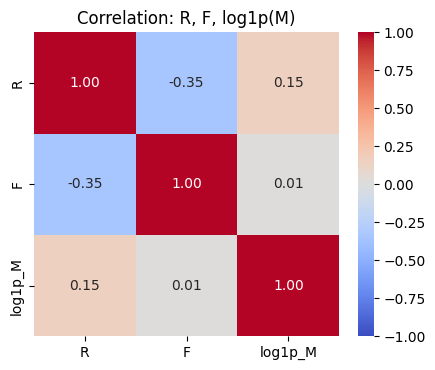

In [48]:
# 2.5.1 Correlations among R, F and log1p(M)
corr_p = df[RFM_COLS].corr()
print("Pearson:"); display(corr_p.round(3))
corr_p.to_csv("data/processed/rfm_correlations_pearson.csv")

plt.figure(figsize=(4.5, 3.8)); sns.heatmap(corr_p, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation: R, F, log1p(M)"); plt.tight_layout(); plt.savefig("figures/rfm_correlation.png", dpi=150); plt.show()

In [49]:
# 2.5.2 Ward on R and F only: same shares, same k, fresh scaling
k_rfm = chosen["HC_RFM"]
X_rf = pd.DataFrame(StandardScaler().fit_transform(df[["R", "F"]]), index=df.index, columns=["R", "F"])
Z_rf = linkage(X_rf.values, method="ward", metric="euclidean")
assign["HC_RF_only"] = cut_tree(Z_rf, n_clusters=k_rfm).ravel()
assert X_rf.index.equals(X_rfm.index)

print(f"k = {k_rfm} | ARI (full RFM vs R,F only) = {adjusted_rand_score(assign['HC_RFM'], assign['HC_RF_only']):.3f}")
print(f"Silhouette: full RFM = {silhouette_score(X_rfm, assign['HC_RFM']):.3f} | R,F only = {silhouette_score(X_rf, assign['HC_RF_only']):.3f}")
display(pd.crosstab(assign["HC_RFM"], assign["HC_RF_only"], rownames=["Full RFM"], colnames=["R,F only"]))

for col in ["HC_RFM", "HC_RF_only"]:
    g = df.assign(Cluster=assign[col]).groupby("Cluster")
    prof = g[["R", "F"]].mean()
    prof["M_median_$bn"] = (g["M"].median() / 1e9).round(1)
    prof["log1p_M_mean"] = g["log1p_M"].mean()
    prof["n"] = g.size()
    print(f"\n{col}: cluster profile"); display(prof.round(2))


k = 2 | ARI (full RFM vs R,F only) = 0.923
Silhouette: full RFM = 0.369 | R,F only = 0.521


"R,F only",0,1
Full RFM,,
0,396,6
1,2,84



HC_RFM: cluster profile


,R,F,M_median_$bn,log1p_M_mean,n
Cluster,,,,,
0,12.56,3.20,15.4,23.64,402
1,57.00,1.98,21.5,23.86,86



HC_RF_only: cluster profile


,R,F,M_median_$bn,log1p_M_mean,n
Cluster,,,,,
0,12.30,3.21,15.5,23.65,398
1,56.17,2.01,20.5,23.80,90


In [50]:
out = assign.join(df[["Sector"]]).join(df[RR_COLS + ["R", "F", "M"]])
out["AsOf"] = "2024-12-31"
out.to_csv("data/processed/cluster_assignments.csv")
print(out.shape); display(out.head())
print("Files in figures/:", sorted(os.listdir("figures")))

SOL = {"Ward return/beta": "HC_RR", "K-means return/beta": "KM_RR",
       "Ward RFM": "HC_RFM", "K-means RFM": "KM_RFM"}

(488, 12)


,HC_RR,KM_RR,HC_RFM,KM_RFM,HC_RF_only,Sector,Mean_Weekly_Return,Weekly_Beta,R,F,M,AsOf
A,0,0,0,0,0,Health Care,0.001121,1.074724,11,2,1.400180e+10,2024-12-31
AAPL,1,1,0,0,0,Information Technology,0.003930,1.174835,11,2,6.233034e+11,2024-12-31
ABBV,0,0,0,0,0,Health Care,0.003749,0.425365,11,3,6.837054e+10,2024-12-31
ABNB,0,1,0,0,0,Consumer Discretionary,0.001475,1.472709,11,3,3.652850e+10,2024-12-31
ABT,0,0,0,0,0,Health Care,0.000971,0.583543,11,1,3.523027e+10,2024-12-31


Files in figures/: ['cluster_scatter.png', 'dendrogram_rfm.png', 'dendrogram_risk_return.png', 'feature_distributions.png', 'k_selection.png', 'rfm_correlation.png', 'rfm_profile_lines.png']


**Task 3**

---



**Task 3.1**

In [51]:
import sqlite3
DB = "data/processed/sp500_mart.db"
if os.path.exists(DB): os.remove(DB)
con = sqlite3.connect(DB)

In [52]:
# Dimensions
dates = adj_close.index
pd.DataFrame({
    "date_key": dates.strftime("%Y%m%d").astype(int),
    "date": dates.strftime("%Y-%m-%d"),
    "week_ending_friday": (dates + pd.to_timedelta((4 - dates.weekday) % 7, unit="D")).strftime("%Y-%m-%d"),
    "month": dates.strftime("%Y-%m"), "year": dates.year}).to_sql("dim_time", con, index=False)

(sp500_df.set_index("Yahoo_Symbol").loc[list(included), ["Symbol", "Security", "GICS Sector"]]
 .reset_index().rename(columns={"Yahoo_Symbol": "ticker", "Symbol": "wiki_symbol",
                                "Security": "name", "GICS Sector": "sector"})
 ).to_sql("dim_share", con, index=False)

bm = bench["Adj Close"].rename("adj_close").to_frame()
bm["benchmark"] = "^GSPC"; bm["date_key"] = bm.index.strftime("%Y%m%d").astype(int)
bm["daily_return"] = bm["adj_close"].pct_change(fill_method=None)
bm.reset_index(drop=True).to_sql("fact_benchmark_daily", con, index=False)

pd.DataFrame({"sector": sorted(sp500_df.set_index("Yahoo_Symbol").loc[list(included), "GICS Sector"].unique())}
             ).to_sql("dim_sector", con, index=False)
pd.DataFrame({"benchmark": ["^GSPC"], "name": ["S&P 500 index"], "price_basis": ["Adj Close (price index)"],
              "source": ["Yahoo Finance via yfinance"]}).to_sql("dim_benchmark", con, index=False)

1

In [53]:
# Fact at the declared grain: one share on one trading day
def lng(w, name):
    long = w.rename_axis(index="Date", columns="ticker").reset_index().melt(
        id_vars="Date", var_name="ticker", value_name=name)
    return long.set_index(["Date", "ticker"])[name]

fact = pd.concat([lng(close[included], "close"), lng(adj_close[included], "adj_close"),
                  lng(volume[included], "volume"), lng(event_flag, "high_volume_flag")], axis=1)
fact = fact.reset_index()
fact["date_key"] = pd.to_datetime(fact["Date"]).dt.strftime("%Y%m%d").astype(int)
fact["traded_value_usd"] = fact["close"] * fact["volume"]
fact["high_volume_flag"] = fact["high_volume_flag"].astype(int)
fact.drop(columns="Date").to_sql("fact_daily_share", con, index=False, chunksize=100000)

490440

In [54]:
# Provenance: source files, retrieval date, library versions
raw_files = sorted(os.listdir("data/raw"))
pd.DataFrame({
    "file": raw_files,
    "wikipedia_retrieved": sp500_df["Retrieved_On"].iloc[0],
    "yfinance_version": yf.__version__,
    "price_window": "2021-01-01 to 2025-01-01 (end exclusive)"}).to_sql("dim_source", con, index=False)

6

In [55]:
# Versioned features and cluster runs
CALC_VERSION = "v1.0"
feat = out.reset_index().rename(columns={"index": "ticker", "Ticker": "ticker"})
pd.DataFrame({"ticker": feat["ticker"], "observation_date": "2024-12-31", "calc_version": CALC_VERSION,
              "baseline_sessions": 20, "rfm_window_sessions": 60,
              "mean_weekly_return": feat["Mean_Weekly_Return"], "weekly_beta": feat["Weekly_Beta"],
              "R": feat["R"], "F": feat["F"], "M_usd": feat["M"]}).to_sql("fact_features", con, index=False)

runs = []
for name, col in SOL.items():
    runs.append(pd.DataFrame({
        "run_id": f"{CALC_VERSION}_{col}", "ticker": out.index, "cluster": out[col].values,
        "algorithm": "Ward (Euclidean)" if col.startswith("HC") else "K-means (k-means++, n_init=20)",
        "k": int(out[col].nunique()), "random_seed": SEED if col.startswith("KM") else None,
        "feature_matrix": "return+beta" if col.endswith("RR") else "R,F,log1p(M)",
        "observation_date": "2024-12-31", "calc_version": CALC_VERSION}))
pd.concat(runs).to_sql("fact_cluster_assignment", con, index=False)

1952

In [56]:
# Example query the mart supports: sector mix of each Ward RFM cluster
q = """SELECT c.run_id, c.cluster, s.sector, COUNT(*) AS n_shares
       FROM fact_cluster_assignment c JOIN dim_share s ON s.ticker = c.ticker
       WHERE c.run_id = 'v1.0_HC_RFM'
       GROUP BY c.run_id, c.cluster, s.sector ORDER BY c.cluster, n_shares DESC LIMIT 8"""
display(pd.read_sql(q, con))
print(pd.read_sql("SELECT name FROM sqlite_master WHERE type='table'", con)["name"].tolist())
con.close()

,run_id,cluster,sector,n_shares
0,v1.0_HC_RFM,0,Industrials,70
1,v1.0_HC_RFM,0,Financials,61
2,v1.0_HC_RFM,0,Information Technology,54
3,v1.0_HC_RFM,0,Health Care,51
4,v1.0_HC_RFM,0,Consumer Discretionary,37
5,v1.0_HC_RFM,0,Real Estate,30
6,v1.0_HC_RFM,0,Consumer Staples,26
7,v1.0_HC_RFM,0,Utilities,21


['dim_time', 'dim_share', 'fact_benchmark_daily', 'dim_sector', 'dim_benchmark', 'fact_daily_share', 'dim_source', 'fact_features', 'fact_cluster_assignment']


**Task 3.2-A: Sector composition, overlap and profile visuals (3.2.1)**

In [57]:
if "out" not in globals():
    out = pd.read_csv("data/processed/cluster_assignments.csv", index_col=0)

overall = out["Sector"].value_counts(normalize=True) * 100

for name in ["Ward return/beta", "Ward RFM"]:
    col = SOL[name]
    ct = pd.crosstab(out[col], out["Sector"])
    pct = ct.div(ct.sum(axis=1), axis=0) * 100
    print(f"\n{name}: sector % within cluster"); display(pct.round(1))
    print("Over-representation = cluster share / overall share"); display((pct / overall.reindex(pct.columns)).round(2))
    pct.round(1).to_csv(f"data/processed/sector_pct_{col}.csv")


Ward return/beta: sector % within cluster


Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
HC_RR,,,,,,,,,,,
0,3.8,9.1,8.1,4.0,15.4,14.1,14.6,11.4,5.3,6.8,7.3
1,5.4,12.0,0.0,4.3,14.1,2.2,22.8,31.5,3.3,3.3,1.1


Over-representation = cluster share / overall share


Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
HC_RR,,,,,,,,,,,
0,0.92,0.94,1.23,0.99,1.02,1.19,0.90,0.75,1.08,1.11,1.19
1,1.33,1.24,0.00,1.06,0.93,0.18,1.41,2.08,0.66,0.53,0.18



Ward RFM: sector % within cluster


Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
HC_RFM,,,,,,,,,,,
0,4.5,9.2,6.5,4.5,15.2,12.7,17.4,13.4,4.0,7.5,5.2
1,2.3,11.6,7.0,2.3,15.1,8.1,10.5,23.3,9.3,0.0,10.5


Over-representation = cluster share / overall share


Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
HC_RFM,,,,,,,,,,,
0,1.09,0.96,0.99,1.09,1.0,1.07,1.08,0.89,0.81,1.21,0.85
1,0.57,1.21,1.06,0.57,1.0,0.68,0.65,1.53,1.89,0.00,1.70


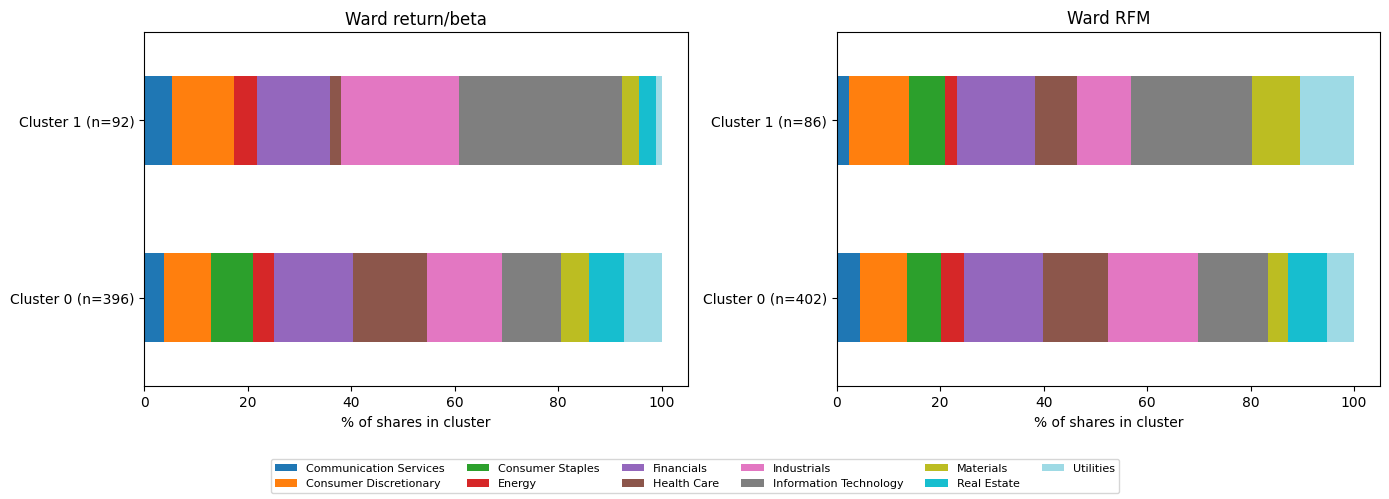

In [58]:
# Visual 1: sector composition per Ward cluster
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for a, (title, col) in zip(ax, [("Ward return/beta", "HC_RR"), ("Ward RFM", "HC_RFM")]):
    pct = pd.crosstab(out[col], out["Sector"], normalize="index") * 100
    n = out[col].value_counts().sort_index()
    pct.index = [f"Cluster {i} (n={n[i]})" for i in pct.index]
    pct.plot(kind="barh", stacked=True, ax=a, colormap="tab20", legend=False)
    a.set(title=title, xlabel="% of shares in cluster")
h, l = ax[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=6, fontsize=8)
plt.tight_layout(rect=[0, 0.1, 1, 1]); plt.savefig("figures/sector_composition.png", dpi=150); plt.show()


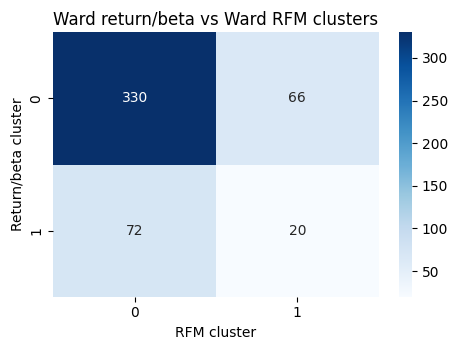

In [59]:
# Visual 2: overlap between the two segmentations
ct = pd.crosstab(out["HC_RR"], out["HC_RFM"], rownames=["Return/beta cluster"], colnames=["RFM cluster"])
plt.figure(figsize=(4.8, 3.6)); sns.heatmap(ct, annot=True, fmt="d", cmap="Blues")
plt.title("Ward return/beta vs Ward RFM clusters"); plt.tight_layout()
plt.savefig("figures/rr_vs_rfm_crosstab.png", dpi=150); plt.show()


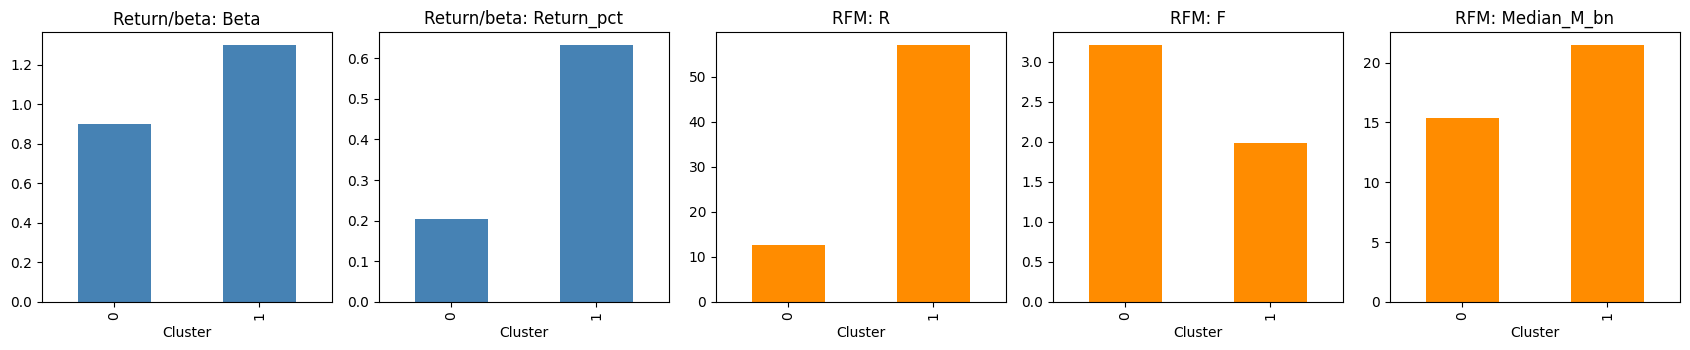

In [60]:
# Visual 3: original-unit profiles side by side
rr = out.groupby("HC_RR")[["Weekly_Beta", "Mean_Weekly_Return"]].mean()
rr["Mean_Weekly_Return"] = rr["Mean_Weekly_Return"] * 100
rr.columns = ["Beta", "Return_pct"]
rf = out.groupby("HC_RFM")[["R", "F"]].mean()
rf["Median_M_bn"] = out.groupby("HC_RFM")["M"].median() / 1e9
fig, ax = plt.subplots(1, 5, figsize=(17, 3.6))
for a, c in zip(ax[:2], rr.columns): rr[c].plot(kind="bar", ax=a, color="steelblue"); a.set(title=f"Return/beta: {c}", xlabel="Cluster")
for a, c in zip(ax[2:], rf.columns): rf[c].plot(kind="bar", ax=a, color="darkorange"); a.set(title=f"RFM: {c}", xlabel="Cluster")
plt.tight_layout(); plt.savefig("figures/profiles_side_by_side.png", dpi=150); plt.show()

**Task 3.2-B: Evidence for the most common Recency value**

---


In [61]:
# Most common Recency value among the shares, and the date it corresponds to
mode_R = int(out["R"].value_counts().idxmax())
mode_date = (OBSERVATION_DATE - pd.Timedelta(days=mode_R)).date()
print(f"Most common R = {mode_R} (latest event {mode_date}):", int((out["R"] == mode_R).sum()), "of", len(out))
display(pd.crosstab(out["HC_RFM"], out["R"] == mode_R, rownames=["Ward RFM"], colnames=[f"R == {mode_R}"]))

Most common R = 11 (latest event 2024-12-20): 354 of 488


R == 11,False,True
Ward RFM,,
0,48,354
1,86,0


**Task 3.2-C: Return dependencies**

---



In [62]:
if "ret_shares" not in globals():
    ret_shares = pd.read_csv("data/processed/weekly_share_returns.csv.gz", index_col=0, parse_dates=True)
corr = ret_shares[out.index].corr()
off = ~np.eye(len(corr), dtype=bool)
print("Mean pairwise weekly-return correlation, all shares:", round(corr.values[off].mean(), 3))

rows = []
for name, col in SOL.items():
    L = out[col].reindex(corr.index).values
    same = L[:, None] == L[None, :]
    rows.append({"Solution": name, "Within clusters": corr.values[same & off].mean(),
                 "Between clusters": corr.values[~same].mean()})
dep = pd.DataFrame(rows).round(3); display(dep); dep.to_csv("data/processed/return_dependency.csv", index=False)

for c in sorted(out["HC_RR"].unique()):
    idx = out.index[out["HC_RR"] == c]
    sub = corr.loc[idx, idx].values
    print(f"Ward return/beta cluster {c} (n={len(idx)}): mean pairwise correlation {sub[np.triu_indices(len(idx), 1)].mean():.3f}")

Mean pairwise weekly-return correlation, all shares: 0.299


,Solution,Within clusters,Between clusters
0,Ward return/beta,0.301,0.297
1,K-means return/beta,0.312,0.281
2,Ward RFM,0.303,0.290
3,K-means RFM,0.304,0.286


Ward return/beta cluster 0 (n=396): mean pairwise correlation 0.297
Ward return/beta cluster 1 (n=92): mean pairwise correlation 0.374
